# Original PC plots with adjustable mean references

Keep `plot_mean_kde_addon.py` beside this notebook. Raw CSV input needs the
original project environment and its `utils.get_features` module. Your
original `plot_test.py` has not been edited.

Each panel still contains an original histogram, an original KDE, and one
reference line. The references have their own controls:

- The original PC0 histogram and KDE use `-abs(pc0)` by default, preserving
  the original workflow that combines the two unknown cell ends on one side.
- The PC0 reference is always drawn from **-1 to 1**. By default its area
  on **[-1, 0] is 1**, matching the folded density histogram. The positive
  half is a symmetric display extension, so the full reference area is 2.
- Set `MEAN_SMOOTHING` below to `False` or `True`, then rerun the later cells.
  This switch is shared by the demo and your CSV plots.
- `pc1_mean_range` sets the PC1 reference's interval and width independently.
- `pc1_profile="circle_chord"` is the default circular chord-length model.
  `"spherocylinder"` includes the cylinder and both hemispherical caps.

The code does not reconstruct cell-head orientation or mirror observations.
Already-folded negative PC0 CSVs are valid inputs for this workflow.


In [1]:
%load_ext dotenv
%dotenv config.env


In [2]:
%load_ext autoreload 
%autoreload 2


In [3]:
from pathlib import Path
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid


from utils.plot_mean_kde_addon import (
    circle_chord_pdf,
    prepare_pc_coordinates,
    plot_pc_mean_kde,
    plot_pc_mean_kde_from_csv,
)


## Reference settings

`False` shows exact geometric profiles with zero endpoints. `True` smooths
only the reference curves. PC0 is normalized **after** smoothing, so its
negative-side area stays 1 in both cases. Neither setting changes the
original histogram or original black KDE. PC1 keeps its existing signed
coordinates and circle-chord model.


In [4]:
MEAN_SMOOTHING = False  # Switch to True to smooth the reference curves; false brings the reference to the x axis
PC0_MEAN_HEIGHT = "negative_area"  # Area 1 on [-1, 0]; total area 2.


## 1. Executable example: PC0 and PC1

These are synthetic localizations inside a cylinder with two hemispherical
caps, with extra sampling in one region. They are not experimental results.
The PC0 reference has area 1 on its negative half. The PC1 reference uses the
pure circle-chord profile with the same radius as the synthetic cell.
Use the switch above to compare smoothing settings. Neither setting affects
the original histogram or original KDE.


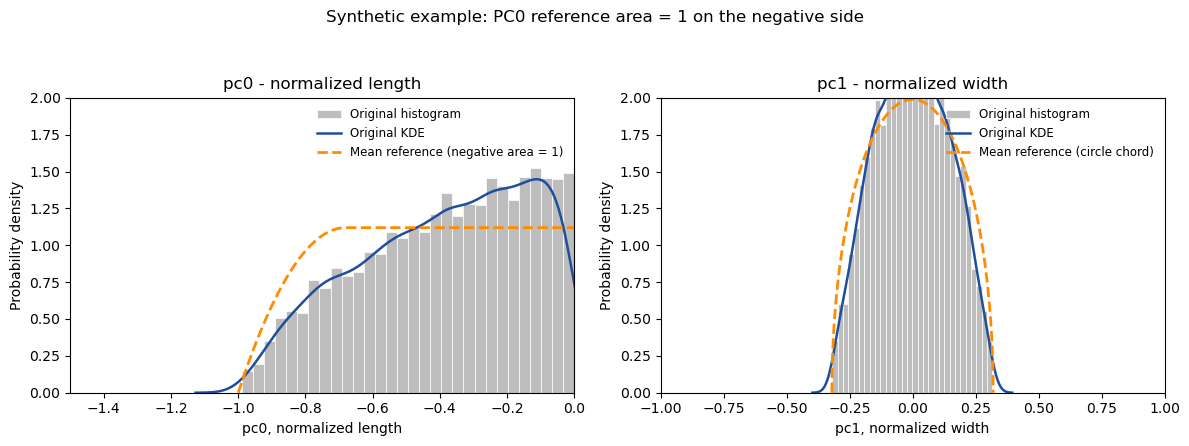

In [5]:
rng = np.random.default_rng(20261005)
CELL_HALF_LENGTH_DEMO = 1.0
CELL_RADIUS_DEMO = 0.32
half_cylinder = CELL_HALF_LENGTH_DEMO - CELL_RADIUS_DEMO
accepted = []
while sum(len(chunk) for chunk in accepted) < 5000:
    xyz = rng.uniform(
        [-CELL_HALF_LENGTH_DEMO, -CELL_RADIUS_DEMO, -CELL_RADIUS_DEMO],
        [CELL_HALF_LENGTH_DEMO, CELL_RADIUS_DEMO, CELL_RADIUS_DEMO],
        size=(18000, 3),
    )
    cap_distance = np.maximum(np.abs(xyz[:, 0]) - half_cylinder, 0.0)
    inside = cap_distance**2 + xyz[:, 1]**2 + xyz[:, 2]**2 <= CELL_RADIUS_DEMO**2
    xyz = xyz[inside]
    enrichment = 0.30 + 0.70 * np.exp(
        -0.5 * ((xyz[:, 0] - 0.25) / 0.30)**2
        -0.5 * (xyz[:, 1] / 0.18)**2
    )
    accepted.append(xyz[rng.random(len(xyz)) < enrichment])
xyz = np.concatenate(accepted)[:5000]
df_demo = pd.DataFrame({"pc0": xyz[:, 0], "pc1": xyz[:, 1]})

fig, panels = plot_pc_mean_kde(
    df_demo,
    mean_mode="spherocylinder",
    fold_pc0=True,
    cell_half_length=CELL_HALF_LENGTH_DEMO,
    cell_radius=CELL_RADIUS_DEMO,
    pc0_mean_height=PC0_MEAN_HEIGHT,
    pc1_mean_range=(-CELL_RADIUS_DEMO, CELL_RADIUS_DEMO),
    pc1_profile="circle_chord",
    mean_smoothing=MEAN_SMOOTHING,
    title="Synthetic example: PC0 reference area = 1 on the negative side",
    show=False,
)
fig.savefig("mean_kde_addon_preview.png", dpi=220, bbox_inches="tight")
plt.show()


### Check the plotted PC0 areas

Histogram area is the sum of each bar's height times its width. Reference
area is the trapezoidal integral of the displayed line. Include `x=0` as
the endpoint when integrating either half.


In [6]:
histogram_area = sum(bar.get_height() * bar.get_width() for bar in panels[0].patches)
reference_x, reference_y = panels[0].lines[-1].get_data()
negative = reference_x <= 0.0
negative_area = trapezoid(reference_y[negative], reference_x[negative])
full_area = trapezoid(reference_y, reference_x)

print(f"PC0 folded histogram area: {histogram_area:.6f}")
print(f"PC0 reference area on [-1, 0]: {negative_area:.6f}")
print(f"PC0 reference area on [-1, 1]: {full_area:.6f}")
np.testing.assert_allclose(histogram_area, 1.0, atol=1e-12, rtol=0)
if PC0_MEAN_HEIGHT == "negative_area":
    np.testing.assert_allclose([negative_area, full_area], [1.0, 2.0], atol=1e-12, rtol=0)


PC0 folded histogram area: 1.000000
PC0 reference area on [-1, 0]: 1.000000
PC0 reference area on [-1, 1]: 2.000000


## 2. What PC1 measures: chord length versus the full cell

For a circular cross-section centered at `c` with radius `R`, the distance
between the two sides of the circle at coordinate `y` is

`chord(y) = 2 * sqrt(R**2 - (y-c)**2)`.

Dividing this by `pi * R**2` gives a unit-area density. This is the
`circle_chord` profile: the cylinder-only transverse reference. Before KDE
smoothing it is exactly a scaled semicircle, with zero height at `c-R` and
`c+R`. It is a filled-circle chord calculation, not a density of the circular
boundary or membrane.

For the whole cell with cylinder length `L` plus two hemispheres, the slice
area is `2*L*sqrt(R**2-y**2) + pi*(R**2-y**2)`. Dividing by the cell volume gives
the `spherocylinder` profile. The second term comes from the two caps combined.
The previous full-cell curve was correct for that assumption; it was not
exactly the pure-circle chord profile. The module now defaults to
`circle_chord`, matching the requested filled-circle projection.
These references implement explicit geometric assumptions; they do not
average the observed heatmap or the black KDE itself.

`pc1_mean_range=(lower, upper)` sets `c=(lower+upper)/2` and `R=(upper-lower)/2`
for the displayed reference. For the full-cell option, the original cell
aspect ratio is retained while stretching the profile to this interval.
Changing this parameter does not filter observations or change histogram bins,
the original KDE, or the PC0 reference.

`mean_smoothing=True` uses the original KDE bandwidth to smooth only the
reference shape. The reference is drawn only inside its selected interval;
Gaussian tails beyond it are omitted, and endpoint heights can be positive.
Use `mean_smoothing=False` for the exact theoretical shape with zero endpoints.
The original KDE remains unchanged either way.


## 3. PC0 area normalization

The original code first folds `pc0` with `-abs(pc0)` and then uses
`stat="density"`. Thus all its bars are on the negative side and their
total area is 1. Folding combines the two cell ends without identifying
which end was the head.

For a symmetric full-cell density `f`, the folded density is
`g(x) = f(x) + f(-x) = 2*f(x)` for `x <= 0`.
The PC0 reference uses the capped-cylinder shape `q(x)` on `[-1, 1]` and
normalizes it using its **negative-half area**, after optional smoothing:

```python
negative = x <= 0.0
reference = q / trapezoid(q[negative], x[negative])
```

This gives area **1 on [-1, 0]**, **1 on [0, 1]**, and **2 on [-1, 1]**.
That is intentional: the negative half is the control density for the folded
histogram; the positive half displays its mirror. The full displayed curve
is not a unit-area probability distribution of the unfolded cell.

The default is `pc0_mean_height="negative_area"`. The earlier `"hist_mean"`
and `"half_hist_mean"` choices remain available for height comparisons,
but they do not guarantee area 1 and should not be selected for this control.
Changing the histogram bin count does not change the area-normalized reference.

The original black KDE is kept as calculated by Seaborn. Gaussian kernels
have tails beyond the cell boundaries, including across zero; consequently
its negative-side area need not equal 1. No clipping or boundary correction
is applied to that original KDE.


## 4. Use original raw CSVs or existing folded PC CSVs

Set your paths and original Dapp_log selection limits, then enable the cell
below. `fold_pc0=True` matches the original negative-half-axis workflow.
It is also safe for a CSV that already contains negative absolute PC0 values.
Use `fold_pc0=False` only when you want to plot the existing values as stored,
such as a different original CSV convention used by `ready_pc_heatmaps`.

Raw CSVs are converted with the original `to_PC_raw(..., absPC=False)` before
folding for the original histogram and KDE. Preparation retains the original
area < 2.5 filter, track-level first Dapp_log values, exclusive Dapp_log bounds,
and track grouping. Existing PC input skips raw conversion and area filtering.


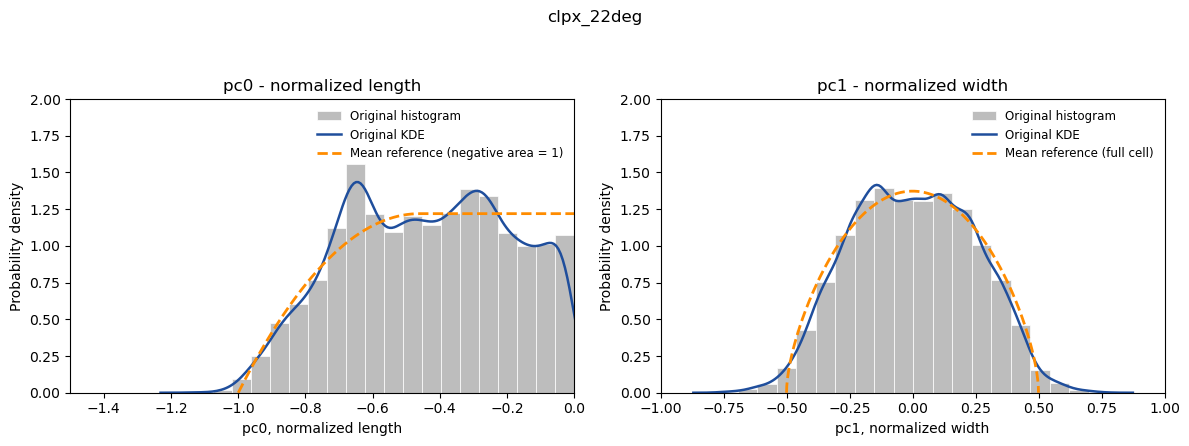

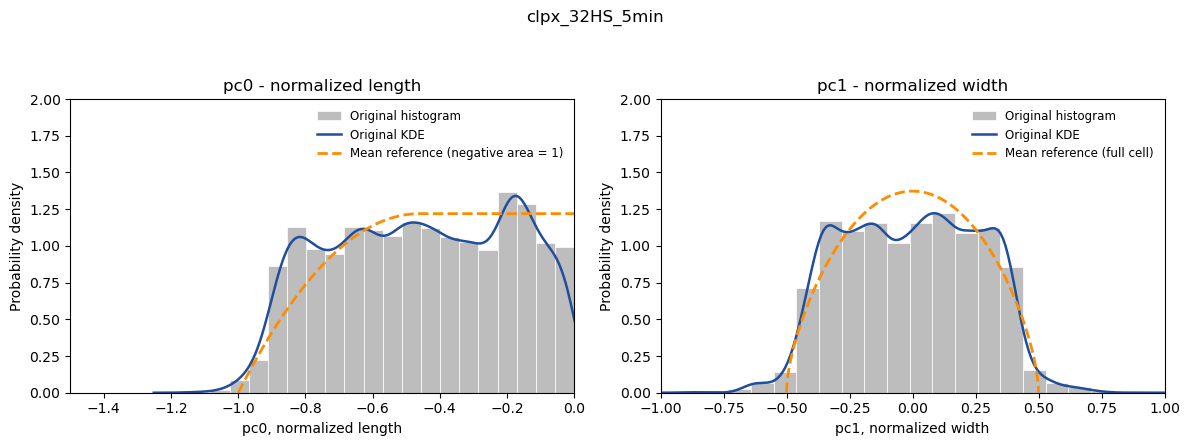

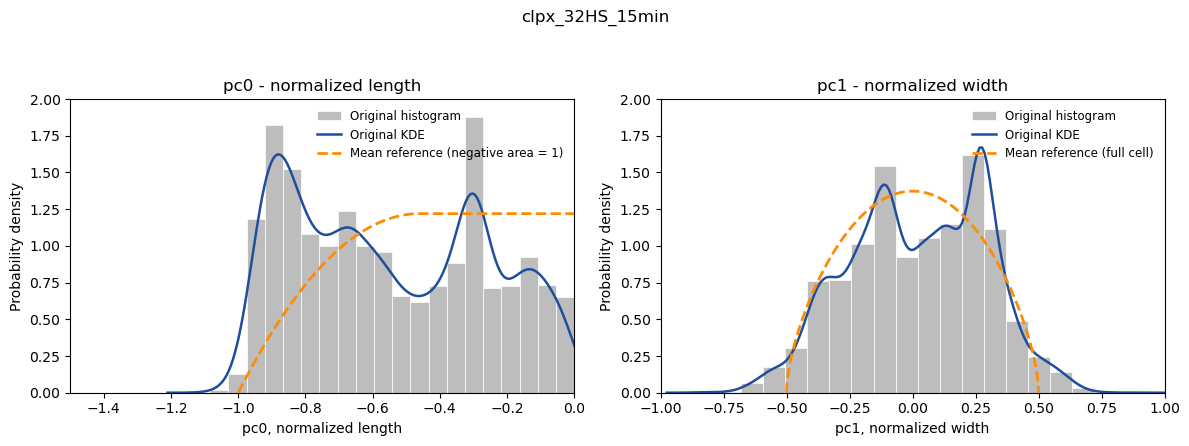

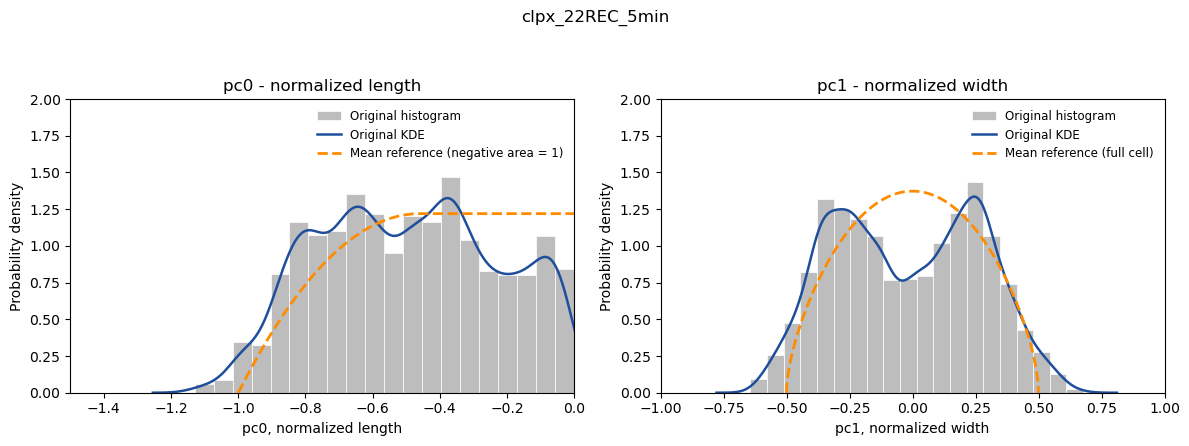

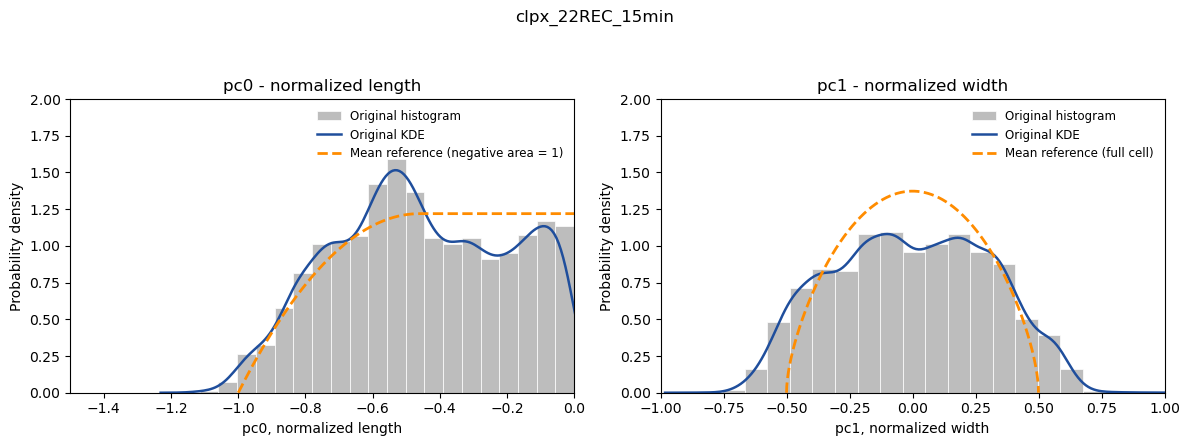

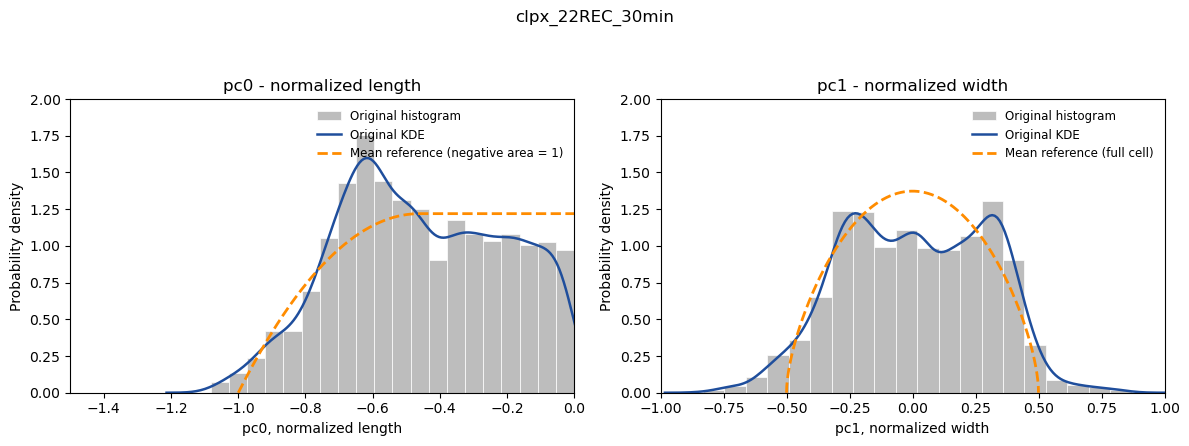

In [7]:
RUN_MY_CSVS = True
DATA_FOLDER = Path("/scratch/project_2009817/SMP_python_images/Eve/non-aggregated_clpx_32_corrected")
COORD_PATHS = ["clpx_22deg.csv", "clpx_32HS_5min.csv", "clpx_32HS_15min.csv", "clpx_22REC_5min.csv", "clpx_22REC_15min.csv", "clpx_22REC_30min.csv"]
#COORD_PATHS = ["clpx_22deg.csv"]
DAPP_RANGES = [(-1.8,0.4),(-1.8,0.4),(-1.8,0.4),(-1.8,0.4),(-1.8,0.4),(-1.8,0.4)]
# Example only: DAPP_RANGES = [(0.0, 0.4), (0.0, 0.4)]

PC1_MEAN_RANGE = (-0.5, 0.5)
PC1_PROFILE = "spherocylinder"   # Or "spherocylinder" for the full cell.
# Reuse MEAN_SMOOTHING and PC0_MEAN_HEIGHT from Reference settings above.

CELL_HALF_LENGTH = 1  # Supply both geometry values in one common scale.
CELL_RADIUS = 0.54      # None for both gives a warned observed-extent approximation.

if RUN_MY_CSVS:
    figures = plot_pc_mean_kde_from_csv(
        folder=DATA_FOLDER,
        coord_paths=COORD_PATHS,
        dapp_ranges=DAPP_RANGES,
        pixel_um=0.106,
        max_area=2.5,
        pc_groupby="track",
        mean_mode="spherocylinder",
        fold_pc0=True,
        cell_half_length=CELL_HALF_LENGTH,
        cell_radius=CELL_RADIUS,
        pc0_mean_height=PC0_MEAN_HEIGHT,
        pc1_mean_range=PC1_MEAN_RANGE,
        pc1_profile=PC1_PROFILE,
        mean_smoothing=MEAN_SMOOTHING,
        hist_bins=20, #was 30
        output_dir=Path("mean_kde_results"),
    )
else:
    print("Set your files, filters, and reference parameters, then enable RUN_MY_CSVS.")


## 5. Plot a DataFrame directly

```python
fig, axes = plot_pc_mean_kde(
    df,
    fold_pc0=True,
    pc0_mean_height="negative_area",
    pc1_mean_range=(-0.4, 0.4),
    pc1_profile="circle_chord",
    mean_smoothing=MEAN_SMOOTHING,
)
```

Both raw and already-PC DataFrames are accepted. For raw data, pass your
`dapp_range`, `pixel_um`, `max_area`, and `pc_groupby` values to this call, or
prepare once and reuse the resulting table:

```python
df_pc = prepare_pc_coordinates(
    df_raw,
    dapp_range=(0.0, 0.4),
    pixel_um=0.106,
    max_area=2.5,
    pc_groupby="track",
)
```

If your original helper module has a different path, pass the actual original
functions via `pc_transform=to_PC_raw, area_func=get_area`.
No replacement PCA implementation is used. The original helper source was
not supplied; its integration was checked with test doubles, while the
reference mathematics and plotting behavior were tested directly.


## 6. Geometry, earlier modes, and module integration

`cell_half_length` and `cell_radius` determine the ideal cell's aspect ratio.
Supply both in a common spatial scale; the half-length includes a cap.
PC0 rescales that geometry to a normalized half-length of exactly 1. PC1
stretches it to `pc1_mean_range` for the full-cell profile. The circle-chord
PC1 profile depends only on its interval, not the cylinder length.
Before smoothing, the PC0 plateau extends from `-(1-R/H)` to `+(1-R/H)`,
where `H=cell_half_length` and `R=cell_radius`. This is still a geometric
model, not a live measurement of the heatmap's rectangular region.

If both geometry values are omitted, observed PC-coordinate extents provide
an approximation and emit a warning. These extents are not measured cell
boundaries. For quantitative interpretation use mask-derived or otherwise
calibrated geometry, matching the coordinate scaling used by `to_PC_raw`.
The functions use one representative shape per dataset, not a per-cell mixture.

The earlier `mean_mode="all_map"` and `mean_mode="by_axis"` options remain.
Their heatmap options and pixel-mean behavior are unchanged. The normalization,
range, profile, and smoothing controls apply to `mean_mode="spherocylinder"`.

The add-on is independent of `plot_test.py`. Replace the add-on beside this
notebook, then restart the kernel or rerun the import/reload cell. Existing
heatmap functions retain their original code. If you choose to append the
new definitions to the original module, import the new plotting entry point
from that module and call it separately.
